# 08 — The Answer from Sales Data
**Stage:** Evaluation

**TL;DR:** Grid data (Notebooks 05–07) sees only *total* demand, so it could not rank the two causes (drought share
24–78%). Official electricity **sales by customer type** can. In FY2023-24, Karnataka's sales rose by **14,549 MU
(+23.5%)**. **Irrigation pump sets took 9,974 MU of that (69%), households only 1,839 MU (13%)**: the pump increase
was **5.4 times** the household increase. Households are the only group that gets free electricity, and part of their
+12.7% is normal growth, so the scheme's own share of the increase is **under 10%**. **Free electricity was a small
part (at most 13%)**, a metered result that holds in all five companies. **Most of the extra electricity went to farm
pump sets, which the rain evidence (Notebooks 04–07) ties mostly to the failed monsoon.**

## 1. Question
How much of the 2023-24 increase in electricity use went to **farm pump sets** (the drought channel) and how much to
**households** (the free-electricity channel)?

**Why this notebook was added (after Notebook 07):** the grid load is one total number per hour, and the drought and
the scheme started at the same time. No model of totals can separate them cleanly, which is why Notebook 07 ended
with a wide range. Power companies, however, report their sales **by tariff category** to the regulator (KERC).

## 2. Expectation *(written before running)*
- If the **drought** was the main cause: pump-set sales (LT-4a) jump far more than household sales (LT-1/LT-2a).
- If **free electricity** was the main cause: household sales jump by a similar or larger amount than pump sets.
- Notebook 06 estimated household growth at +7–11% from news reports, i.e. ≤ ~13% of the surge. Official data should
  land near that if it was right.

## 3. Data used
`references/escom_sales_by_category.csv`, transcribed by hand (with the source of every number) from:

| Year | Source | What it is |
|---|---|---|
| FY2022-23 | Each ESCOM's **Tariff Filing 2024** to KERC: BESCOM Ch.3 Table 3.1; MESCOM and CESC Format D-2; HESCOM Ch.4 sales table; GESCOM Ch.3 Table 45 | actual sales, from audited accounts |
| FY2023-24 | **KERC Combined Tariff Order 2025**, Tables 4.3A–4.3E | actual sales, approved by the regulator |

- **Households** = LT-1 (BJ/KJ) + LT-2(a) (domestic) in FY23; in FY24 KERC reports these merged as LT-1.
- **Pump sets** = LT-4(a), irrigation pump sets up to 10 HP (unmetered; their use is *estimated*, see Caveats).
- **Total** = all LT + HT categories (open-access and SEZ supply excluded, so both years are on the same basis).
- The PDFs and Excel files are in `data/external/` (not in Git; ~70 MB). The two Excel-based companies are
  re-checked against the original files below when those files are present.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src import config, plots

plots.setup()
pd.set_option("display.width", 200)
sales = pd.read_csv(config.ROOT / "references" / "escom_sales_by_category.csv")
sales[["escom", "fy", "households_mu", "pumpsets_mu", "total_lt_ht_mu"]]

,escom,fy,households_mu,pumpsets_mu,total_lt_ht_mu
0,BESCOM,FY2022-23,8175.87,6278.30,29356.46
1,MESCOM,FY2022-23,1649.84,1643.06,5524.11
2,CESC,FY2022-23,1215.36,2679.70,6531.99
3,HESCOM,FY2022-23,1869.65,6476.23,11957.74
4,GESCOM,FY2022-23,1620.76,3519.08,8440.51
5,BESCOM,FY2023-24,9340.66,10221.54,36185.07
6,MESCOM,FY2023-24,1830.33,2534.07,6834.77
7,CESC,FY2023-24,1362.68,4364.79,8667.12
8,HESCOM,FY2023-24,2098.23,8933.42,15095.30
9,GESCOM,FY2023-24,1738.13,4516.43,9577.45


## 4. Analysis
### Step 4.1 — Validate the transcription
Three checks: (1) the five companies' FY24 figures must add up to KERC's state totals (Table 4.3F); (2) the overall
growth must match what KERC itself wrote: *"about 24%… The growth for FY2023-24, excluding IP sets, is also about
12%"*; (3) where the original Excel files are available, the FY23 numbers must match them exactly.

In [2]:
state = sales.groupby("fy")[["households_mu", "pumpsets_mu", "total_lt_ht_mu", "total_grand_mu"]].sum()
fy24 = state.loc["FY2023-24"]
kerc_43f = {"households_mu": 16370.03, "pumpsets_mu": 30570.25, "total_lt_ht_mu": 76359.71, "total_grand_mu": 76910.50}
for k, v in kerc_43f.items():
    print(f"{k:16s} sum of ESCOMs {fy24[k]:10,.2f}   KERC Table 4.3F {v:10,.2f}   match: {abs(fy24[k] - v) < 0.05}")

g = state.total_grand_mu; p = state.pumpsets_mu
print(f"\nTotal growth FY24 vs FY23 (grand totals): {(g.iloc[1] / g.iloc[0] - 1) * 100:.1f}%   (KERC: 'about 24%')")
print(f"Growth excluding IP sets:                 {((g - p).iloc[1] / (g - p).iloc[0] - 1) * 100:.1f}%   (KERC: 'about 12%')")

households_mu    sum of ESCOMs  16,370.03   KERC Table 4.3F  16,370.03   match: True
pumpsets_mu      sum of ESCOMs  30,570.25   KERC Table 4.3F  30,570.25   match: True
total_lt_ht_mu   sum of ESCOMs  76,359.71   KERC Table 4.3F  76,359.71   match: True
total_grand_mu   sum of ESCOMs  76,910.50   KERC Table 4.3F  76,910.50   match: True

Total growth FY24 vs FY23 (grand totals): 24.3%   (KERC: 'about 24%')
Growth excluding IP sets:                 12.2%   (KERC: 'about 12%')


In [3]:
# Re-check MESCOM and CESC FY23 against their original Excel filings (Format D-2), if the files are present
ext = config.ROOT / "data" / "external"
files = {"MESCOM": ext / "MESCOM_Filing2024_Formats.xlsx", "CESC": ext / "CESC_Filing2024_Formats.xlsx"}
ACTUAL_MU_COL = {"MESCOM": 9, "CESC": 8}      # column of 'Actuals as per audited accounts: Energy Sales (MU)'
HH_CODES = {"MESCOM": ["LT-1 <18", "LT-1>18", "LT-2 (a)"], "CESC": ["LT-1", "LT-2 (a)"]}
for escom, f in files.items():
    if not f.exists():
        print(f"{escom}: original file not present, skipped"); continue
    d2 = pd.read_excel(f, sheet_name="D-2", header=None)
    lab = d2.astype(str).apply(lambda col: col.str.strip())
    def mu(code):   # sum of 'actual MU' over every row labelled with this tariff code
        return d2.loc[lab.eq(code).any(axis=1), ACTUAL_MU_COL[escom]].astype(float).sum()
    hh = sum(mu(c) for c in HH_CODES[escom])
    ip = mu("LT-4 (a)")
    ref = sales[(sales.escom == escom) & (sales.fy == "FY2022-23")].iloc[0]
    print(f"{escom}: pump sets from Excel {ip:,.2f} vs CSV {ref.pumpsets_mu:,.2f}"
          + f" | households from Excel {hh:,.2f} vs CSV {ref.households_mu:,.2f}")

MESCOM: pump sets from Excel 1,643.06 vs CSV 1,643.06 | households from Excel 1,649.84 vs CSV 1,649.84


CESC: pump sets from Excel 2,679.70 vs CSV 2,679.70 | households from Excel 1,215.36 vs CSV 1,215.36


### Step 4.2 — Where did the extra electricity go?

In [4]:
s = state[["households_mu", "pumpsets_mu", "total_lt_ht_mu"]].copy()
s["other_mu"] = s.total_lt_ht_mu - s.households_mu - s.pumpsets_mu
inc = (s.loc["FY2023-24"] - s.loc["FY2022-23"])
tab = pd.DataFrame({"FY2022-23 (MU)": s.loc["FY2022-23"], "FY2023-24 (MU)": s.loc["FY2023-24"],
                    "increase (MU)": inc, "growth %": inc / s.loc["FY2022-23"] * 100,
                    "share of total increase %": inc / inc["total_lt_ht_mu"] * 100,
                    "average extra load (MW)": inc / 8784 * 1000})   # FY24 has 366 days (Feb 2024)
tab.index = ["Households (incl. free electricity)", "Pump sets (mostly drought)", "Total", "Everything else"]
tab = tab.loc[["Pump sets (mostly drought)", "Households (incl. free electricity)", "Everything else", "Total"]]
print(f"Pump-set increase ÷ household increase: {inc.pumpsets_mu / inc.households_mu:.1f}×")
tab.round(1)

Pump-set increase ÷ household increase: 5.4×


,FY2022-23 (MU),FY2023-24 (MU),increase (MU),growth %,share of total increase %,average extra load (MW)
Pump sets (mostly drought),20596.4,30570.2,9973.9,48.4,68.6,1135.5
Households (incl. free electricity),14531.5,16370.0,1838.5,12.7,12.6,209.3
Everything else,26683.0,29419.4,2736.5,10.3,18.8,311.5
Total,61810.8,76359.7,14548.9,23.5,100.0,1656.3


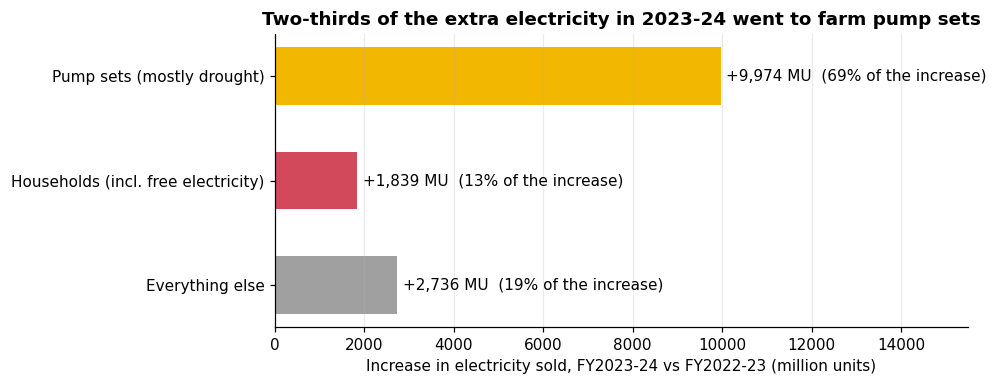

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
rows = tab.drop("Total")
colors = [plots.COLORS["solar"], plots.COLORS["highlight"], plots.COLORS["muted"]]
ax.barh(rows.index, rows["increase (MU)"], color=colors, height=0.55)
for i, (name, r) in enumerate(rows.iterrows()):
    ax.text(r["increase (MU)"] + 120, i, f"+{r['increase (MU)']:,.0f} MU  ({r['share of total increase %']:.0f}% of the increase)",
            va="center", fontsize=10)
ax.invert_yaxis(); ax.set_xlim(0, 15500)
ax.set_xlabel("Increase in electricity sold, FY2023-24 vs FY2022-23 (million units)")
ax.set_title("Two-thirds of the extra electricity in 2023-24 went to farm pump sets")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plots.save(fig, "08_sales_increase"); plt.show()

_What I see:_ pump-set sales rose by almost half (+48%), households by about an eighth (+13%). In absolute terms the
pump increase is more than five times the household increase.

### Step 4.3 — Is it the same in every company?
*Why:* a state total can hide one unusual company. If the drought explanation is right, the pattern should appear in
all five, including Bengaluru's BESCOM, which has the most households.

In [6]:
w = sales.pivot(index="escom", columns="fy", values=["households_mu", "pumpsets_mu"])
by = pd.DataFrame({
    "household increase (MU)": w["households_mu"]["FY2023-24"] - w["households_mu"]["FY2022-23"],
    "pump-set increase (MU)": w["pumpsets_mu"]["FY2023-24"] - w["pumpsets_mu"]["FY2022-23"],
    "household growth %": (w["households_mu"]["FY2023-24"] / w["households_mu"]["FY2022-23"] - 1) * 100,
    "pump-set growth %": (w["pumpsets_mu"]["FY2023-24"] / w["pumpsets_mu"]["FY2022-23"] - 1) * 100,
}).loc[["BESCOM", "HESCOM", "GESCOM", "CESC", "MESCOM"]]
by["pump ÷ household"] = by["pump-set increase (MU)"] / by["household increase (MU)"]
by.round(1)

,household increase (MU),pump-set increase (MU),household growth %,pump-set growth %,pump ÷ household
escom,,,,,
BESCOM,1164.8,3943.2,14.2,62.8,3.4
HESCOM,228.6,2457.2,12.2,37.9,10.7
GESCOM,117.4,997.4,7.2,28.3,8.5
CESC,147.3,1685.1,12.1,62.9,11.4
MESCOM,180.5,891.0,10.9,54.2,4.9


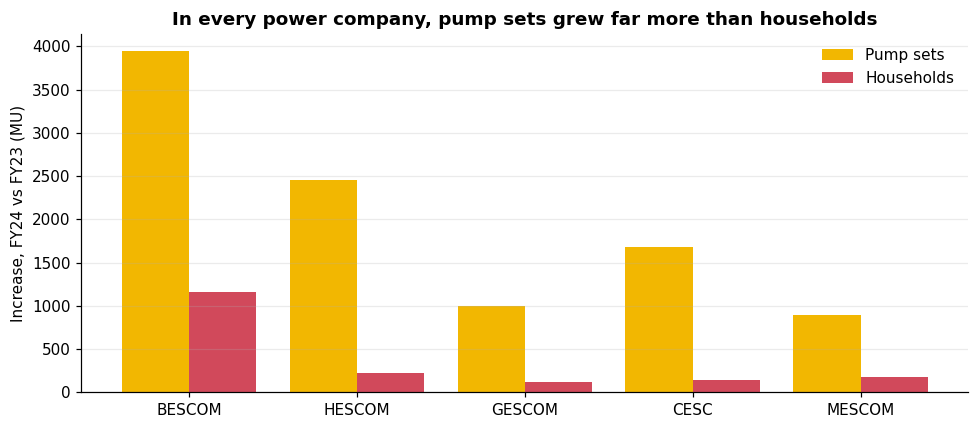

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(by))
ax.bar(x - 0.2, by["pump-set increase (MU)"], 0.4, color=plots.COLORS["solar"], label="Pump sets")
ax.bar(x + 0.2, by["household increase (MU)"], 0.4, color=plots.COLORS["highlight"], label="Households")
ax.set_xticks(x, by.index)
ax.set_ylabel("Increase, FY24 vs FY23 (MU)")
ax.set_title("In every power company, pump sets grew far more than households")
ax.legend(); ax.grid(axis="x", visible=False)
plt.tight_layout(); plots.save(fig, "08_by_escom"); plt.show()

_What I see:_ the pattern holds in **all five companies**. The ratio is lowest in BESCOM (Bengaluru, many households,
3.4×) and highest in CESC, HESCOM and GESCOM (8–11×). The number of pump-set connections barely changed (BESCOM
reports +18,552, about 2%), so the jump is more use per pump, which is what a drought does.

### Step 4.4 — How much of the household increase is the scheme?
Household sales grow every year even without a scheme. Subtracting a normal growth rate gives the part that could be
due to free electricity. The grid trend (Notebook 05) is ~3%/yr; 6% is a generous upper value.

In [8]:
hh23, d_hh, d_tot = s.loc["FY2022-23", "households_mu"], inc["households_mu"], inc["total_lt_ht_mu"]
sens = pd.DataFrame([{"normal household growth": f"{g:.0%}", "normal increase (MU)": hh23 * g,
                      "extra household use (MU)": d_hh - hh23 * g,
                      "share of total increase %": (d_hh - hh23 * g) / d_tot * 100} for g in (0.0, 0.03, 0.04, 0.06)])
sens.round(1)

,normal household growth,normal increase (MU),extra household use (MU),share of total increase %
0,0%,0.0,1838.5,12.6
1,3%,435.9,1402.6,9.6
2,4%,581.3,1257.3,8.6
3,6%,871.9,966.7,6.6


_What I see:_ even if all household growth were caused by the scheme, it would be 13% of the increase. With any
normal growth taken out, the scheme's share is **7–10%**. That agrees with Notebook 06's estimate (≤13%), which used
news reports; the official figures confirm it.

## 5. Result
**Free electricity was a small part (at most 13% of the increase). Most of the extra electricity went to farm pump
sets, which the rain evidence ties mostly to the failed monsoon.**

| Where the extra electricity went (FY24 vs FY23) | Increase | Share of the increase |
|---|---|---|
| 🚜 Irrigation pump sets (mostly drought) | **+9,974 MU (+48%)** | **69%** |
| 🏠 Households (free electricity + normal growth) | +1,839 MU (+13%) | 13% |
| 🏭 Everything else (shops, industry, water supply…) | +2,736 MU (+10%) | 19% |
| **Total** | **+14,549 MU (+23.5%)** | 100% |

- The pump increase was **5.4×** the household increase, and the pattern holds in **all five** power companies.
- After removing normal growth, the scheme accounts for roughly **7–10%** of the increase.
- **What is proven and what is not:** the household side is direct and metered, so the cap on free electricity is
  solid. The sales data separates *customer types*, not *causes*: that the pump-set growth was the drought rests on
  the rain evidence in Notebooks 04–07 (demand tracked rain, the surge sat in farm-pump hours, the 2016 drought looked
  similar), not on this table alone.
- **How this fits with Notebooks 05–07:** the lasting increase in the grid data (~1,300–1,400 MW, still present in
  normal-rain 2024) is far larger than the household increase (~209 MW on average in FY24). So most of it must be pump
  sets or other customers. If pump use stayed high after the rain returned, that part of the pump growth is **not**
  drought. FY2024-25 sales will show this.
- **Different measures:** the 69% is a share of the year-on-year increase (against a wet year, including normal
  growth); the grid's 24–78% is a share of demand above a model's expectation. They are not two estimates of the same
  number.

**Expectations vs results:** pump sets far above households ✓; Notebook 06's ≤13% estimate ✓.

Figures: `08_sales_increase`, `08_by_escom`.

## 6. Caveats
- **Most pump sets are not metered.** Their use is estimated by the power companies (feeder readings minus metered
  use), and objectors in KERC's hearings argue that some line losses are booked as pump use. So the pump figure may be
  overstated. The state reimburses the companies for pump-set power as a subsidy, so they also have a financial reason
  to book more under pump sets. **Household use is metered**, so the conclusion that free electricity was a small part
  holds either way.
- **The lasting increase is unexplained by this data.** It is too large to be households, so part of the pump-set
  growth (or "everything else") may be lasting rather than drought-driven.
- **Financial years, not months.** FY2023-24 runs April 2023 – March 2024 and includes four months before the scheme
  started (and a dry June–July). The Aug–Oct 2023 peak cannot be isolated from annual data.
- **Category definitions changed** between the two years (BJ/KJ and LT-2a were merged into LT-1). Both years are
  added up the same way here, but small reclassifications are possible.
- **FY23 was a wet year** (low pump use), which makes the FY24 jump look larger than against an average year.
- **Hand transcription** from scanned PDFs for BESCOM, HESCOM and GESCOM FY23. The FY24 sums match KERC's state totals
  exactly, and the overall growth matches KERC's own statement, which makes large errors unlikely.
- FY2024-25 actuals are not yet published, so this notebook cannot show what the lasting increase consisted of in 2024.

## 7. Next
- When KERC publishes the FY2024-25 actuals (next tariff order), repeat this comparison: if pump-set sales fell back
  and household sales stayed high, that measures the lasting household effect directly.
- **Communicate:** headline in the README and report: "Free electricity was a small part (at most 13%); most of the
  extra electricity went to farm pump sets, which the rain evidence ties to the failed monsoon".